## Planning:
- Load data
- Check variable and target
- Check correlation between numeric variable
- Check output to variable impact (using KDE distribution)

In [43]:
import pandas as pd
import numpy as np

In [44]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submit = pd.read_csv("sample_submission.csv")

In [45]:
train.head(3)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False


In [54]:
train.shape

(699635, 23)

In [55]:
test.shape

(299844, 22)

In [56]:
test.head(3)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco


In [57]:
submit.head(3)

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573


In [58]:
train.groupby('satisfaction')['id'].count()

satisfaction
False    389296
True     310339
Name: id, dtype: int64

In [59]:
# proportion of each class
train['satisfaction'].value_counts(normalize=True)

satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64

In [60]:
# good proportion

In [61]:
# check data type
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [3]:
# missing data
# calculate percentage missing value in training data
train_missing = pd.DataFrame(train.isna().sum()).reset_index()

In [63]:
train_missing

,index,0
0,id,0
1,Age,0
2,Flight Distance,0
3,Inflight wifi service,0
4,Departure/Arrival time convenient,0
5,Ease of Online booking,0
6,Gate location,0
7,Food and drink,0
8,Online boarding,0
9,Seat comfort,0


In [4]:
train[train['Arrival Delay in Minutes'].isna()]

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
6395,6395,58,679,2,4,2,3,5,2,5,...,4,5,5,6,NaN,Male,Loyal Customer,Personal Travel,Eco,False
6556,6556,62,925,3,5,3,2,2,3,3,...,5,5,3,0,NaN,Male,Loyal Customer,Personal Travel,Eco,False
10659,10659,13,2475,3,3,3,3,3,1,2,...,3,1,1,36,NaN,Male,disloyal Customer,Business travel,Eco,False
11246,11246,17,646,2,2,3,4,4,3,4,...,4,4,4,38,NaN,Female,disloyal Customer,Business travel,Eco,False
17491,17491,31,1325,2,5,2,3,3,2,3,...,4,3,3,1,NaN,Male,Loyal Customer,Personal Travel,Eco,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678415,678415,44,507,2,4,2,1,1,1,2,...,5,3,1,0,NaN,Male,Loyal Customer,Personal Travel,Eco,False
679402,679402,23,1023,2,1,2,4,5,2,5,...,4,3,5,40,NaN,Female,Loyal Customer,Personal Travel,Eco,False
682118,682118,40,692,4,1,1,1,4,4,4,...,1,2,4,0,NaN,Male,Loyal Customer,Business travel,Eco,True
682337,682337,57,2732,5,5,5,5,5,5,4,...,5,4,4,0,NaN,Female,Loyal Customer,Business travel,Business,True


In [65]:
train[train['Departure Delay in Minutes']>0]

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False
11,11,28,2636,2,4,4,4,2,2,2,...,4,1,2,25,24.0,Female,Loyal Customer,Business travel,Business,False
17,17,41,631,2,5,2,1,1,2,1,...,5,3,1,24,18.0,Female,Loyal Customer,Personal Travel,Eco,False
20,20,57,866,1,5,1,2,1,1,1,...,4,3,1,3,0.0,Male,Loyal Customer,Personal Travel,Eco,False
29,29,28,1452,5,5,5,2,4,5,4,...,2,4,4,6,0.0,Female,disloyal Customer,Business travel,Business,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699578,699578,29,1416,3,3,3,3,1,3,1,...,3,2,1,10,0.0,Male,disloyal Customer,Business travel,Eco,True
699598,699598,18,462,1,4,1,2,4,1,4,...,4,3,4,19,16.0,Male,Loyal Customer,Personal Travel,Eco,False
699606,699606,34,2475,3,3,3,3,1,3,3,...,3,3,1,24,0.0,Female,disloyal Customer,Business travel,Business,False
699620,699620,24,584,3,2,3,2,3,3,3,...,3,4,3,4,0.0,Male,disloyal Customer,Business travel,Eco,False


In [46]:
train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(train['Arrival Delay in Minutes'].mean())

In [47]:
test['Arrival Delay in Minutes'] = test['Arrival Delay in Minutes'].fillna(test['Arrival Delay in Minutes'].mean())

In [48]:
# check correlation of numeric variable
# take all column numeric column
numeric_cols = train.drop(columns='id').select_dtypes(include='number').columns.tolist()

In [96]:
numeric_cols

['Age',
 'Flight Distance',
 'Inflight wifi service',
 'Departure/Arrival time convenient',
 'Ease of Online booking',
 'Gate location',
 'Food and drink',
 'Online boarding',
 'Seat comfort',
 'Inflight entertainment',
 'On-board service',
 'Leg room service',
 'Baggage handling',
 'Checkin service',
 'Cleanliness',
 'Departure Delay in Minutes',
 'Arrival Delay in Minutes']

In [49]:
non_numeric_cols = train.select_dtypes(exclude='number').columns.tolist()

In [98]:
non_numeric_cols

['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

In [99]:
matrix_corr = train[numeric_cols].corr()

In [100]:
matrix_corr

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
Age,1.000000,0.190709,0.043137,0.050863,0.043831,0.004095,0.048203,0.287612,0.229095,0.130684,0.096475,0.086409,-0.032758,0.069099,0.109591,-0.010311,-0.012879
Flight Distance,0.190709,1.000000,0.046614,-0.036590,0.087908,0.019533,0.083711,0.310864,0.233666,0.206140,0.170306,0.194532,0.098368,0.104633,0.147663,-0.006978,-0.012246
Inflight wifi service,0.043137,0.046614,1.000000,0.423833,0.771977,0.426632,0.145407,0.488734,0.165905,0.236276,0.133350,0.150859,0.115901,0.057094,0.166201,-0.015971,-0.020246
Departure/Arrival time convenient,0.050863,-0.036590,0.423833,1.000000,0.550840,0.507193,0.006107,0.071405,0.008762,-0.007757,0.087505,0.005987,0.087606,0.110153,0.010944,-0.002309,-0.003143
Ease of Online booking,0.043831,0.087908,0.771977,0.550840,1.000000,0.580151,0.041581,0.403263,0.066317,0.079558,0.053308,0.090667,0.041568,0.018864,0.047616,-0.005112,-0.006848
Gate location,0.004095,0.019533,0.426632,0.507193,0.580151,1.000000,0.011033,0.019974,0.017508,0.021315,-0.027713,0.002364,-0.006403,-0.043934,0.009139,0.003887,0.004770
Food and drink,0.048203,0.083711,0.145407,0.006107,0.041581,0.011033,1.000000,0.263389,0.656050,0.656487,0.089891,0.053437,0.057830,0.092351,0.678229,-0.013869,-0.020031
Online boarding,0.287612,0.310864,0.488734,0.071405,0.403263,0.019974,0.263389,1.000000,0.472677,0.374625,0.218875,0.184671,0.112208,0.210361,0.372450,-0.020194,-0.030750
Seat comfort,0.229095,0.233666,0.165905,0.008762,0.066317,0.017508,0.656050,0.472677,1.000000,0.744750,0.194851,0.156010,0.111178,0.193581,0.762597,-0.016830,-0.027233
Inflight entertainment,0.130684,0.206140,0.236276,-0.007757,0.079558,0.021315,0.656487,0.374625,0.744750,1.000000,0.425282,0.325798,0.394967,0.166283,0.750996,-0.020168,-0.031074


In [101]:
# correlation
import seaborn as sns
import matplotlib.pyplot as plt

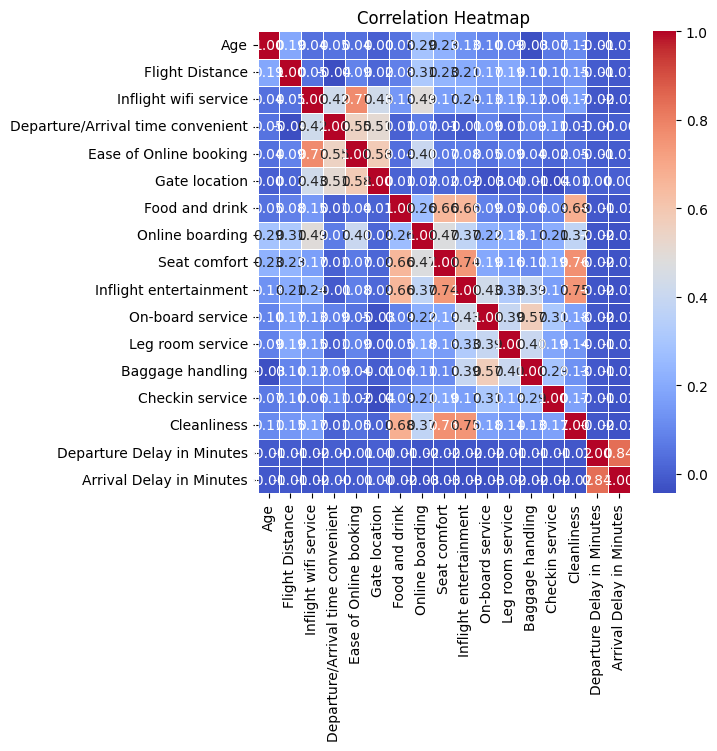

In [74]:
plt.figure(figsize=(6,6))
sns.heatmap(matrix_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [75]:
# If overall flight is pleasant, other variable have high correlation

In [76]:
# lets check the connection between target and input

In [102]:
PALETTE = {True: "#4C72B0", False: "#DD8452"}  

In [103]:
sample_df = train.sample(n=15000, random_state=42)

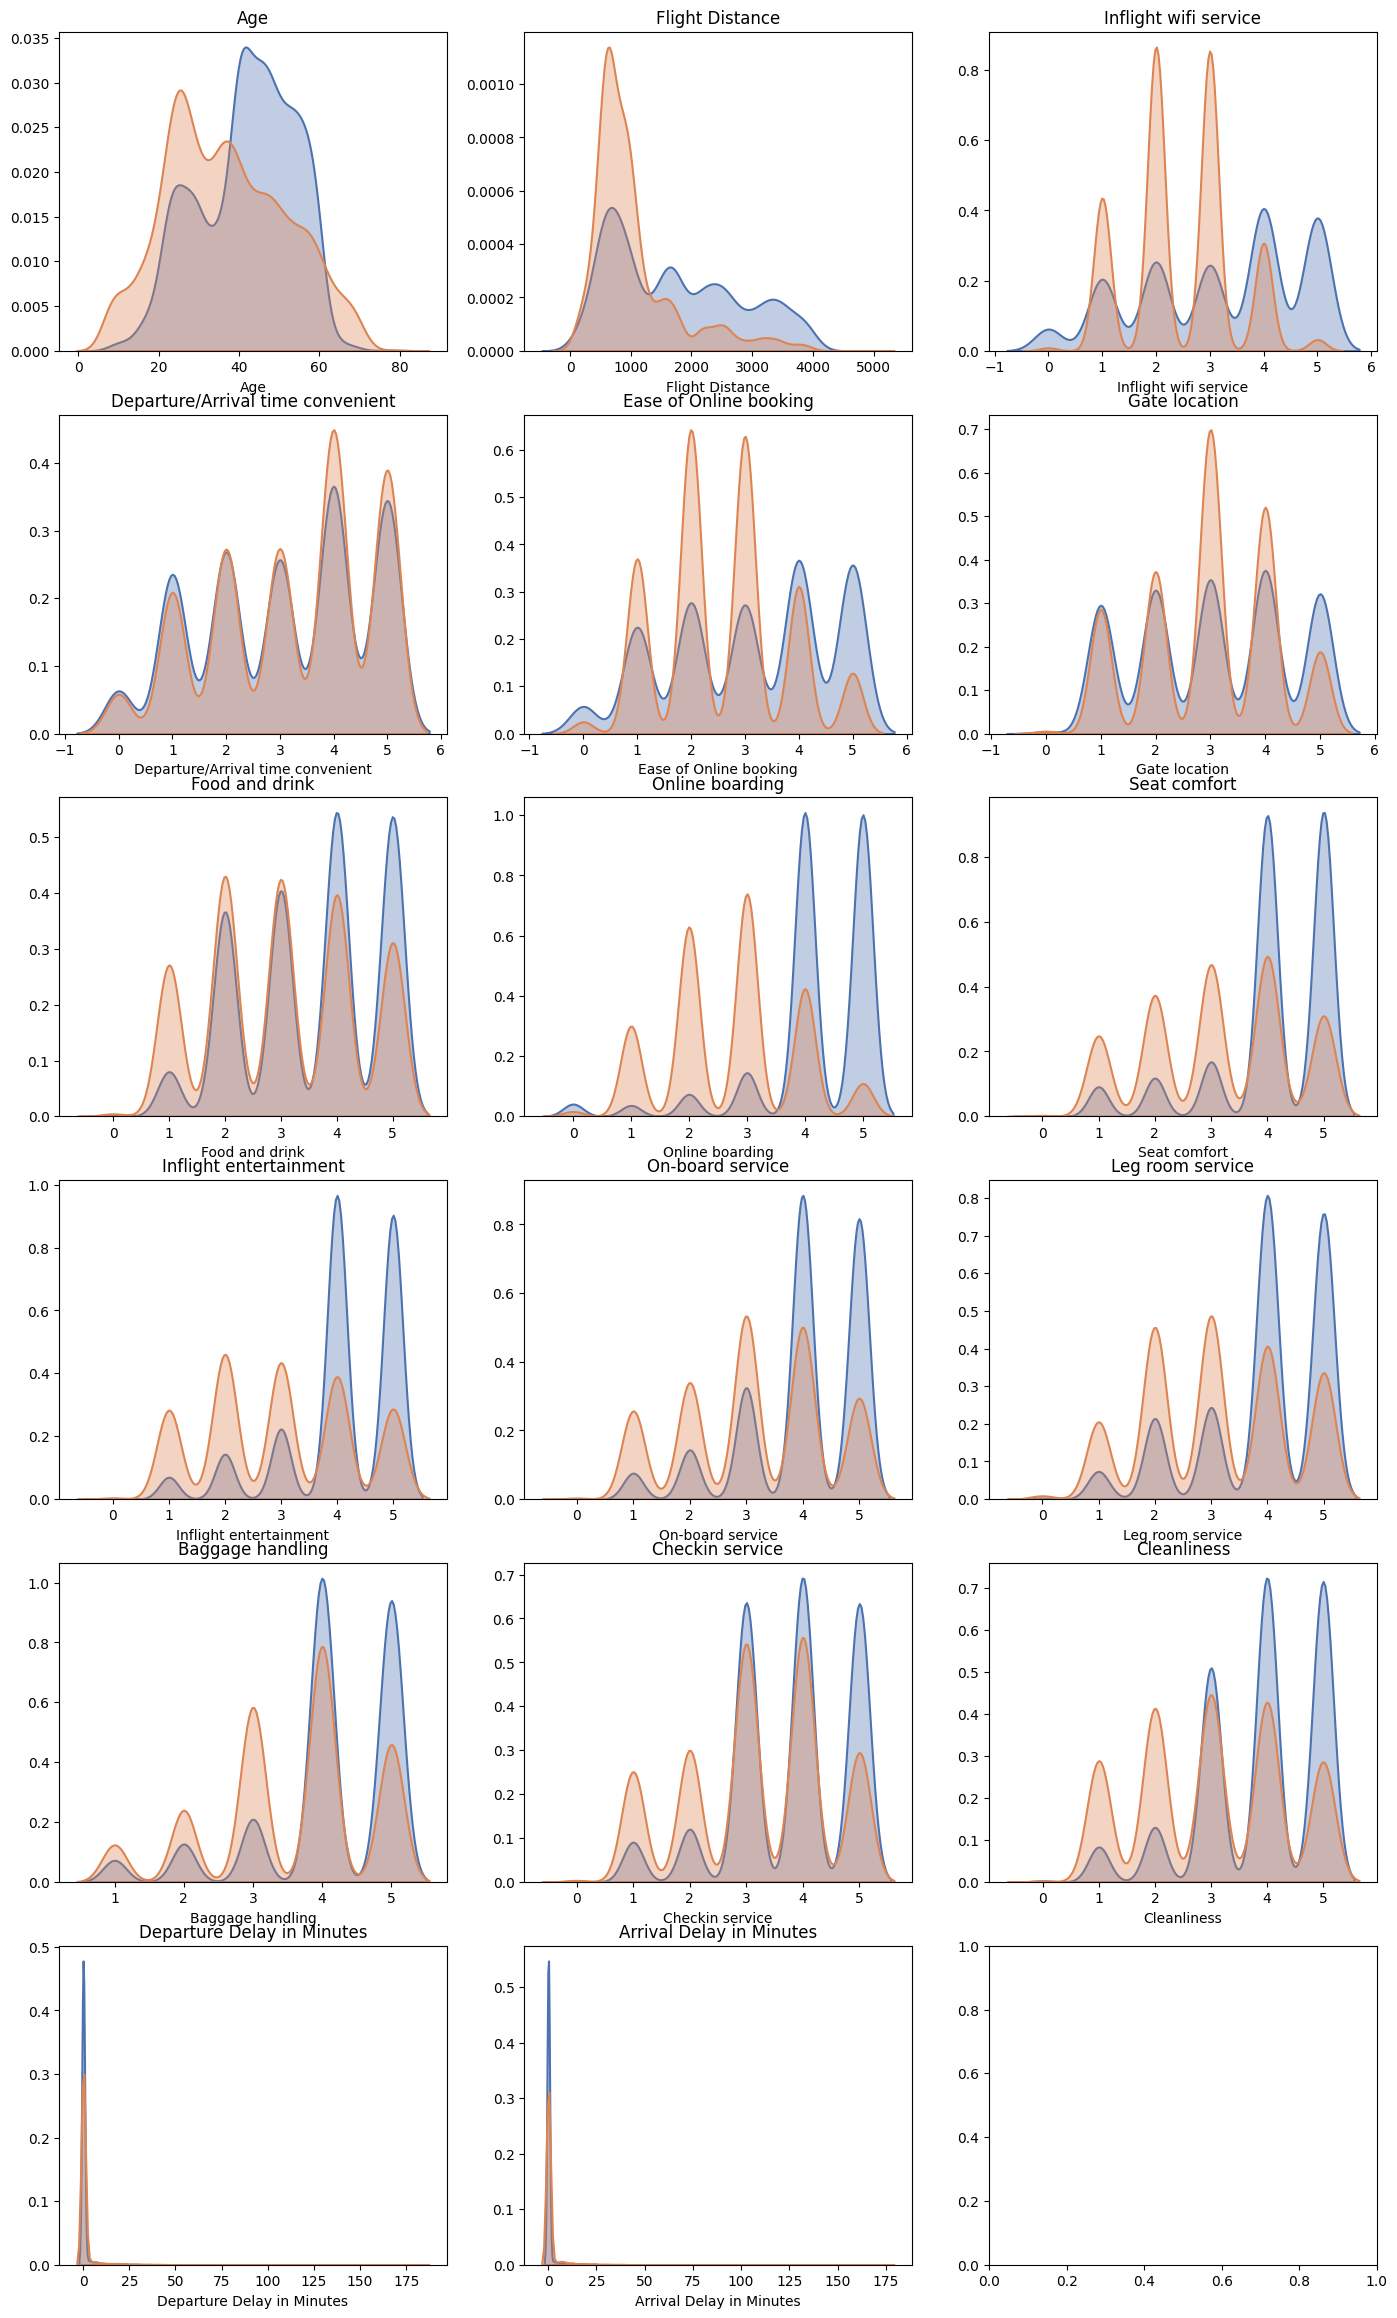

In [79]:
fig, axes = plt.subplots(6, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), numeric_cols):
    for label, color in PALETTE.items():
        sns.kdeplot(sample_df.loc[sample_df["satisfaction"] == label, col].dropna(),
                    ax=ax, 
                    fill=True, 
                    alpha=0.35, 
                    color=color, 
                    linewidth=1.5,
                    label=str(label))
    ax.set_title(col)
    ax.set_ylabel("")

## Basic Modeling

Data preparation - Create Dummy variable

In [50]:
# train_dummy = pd.get_dummies(train, columns=non_numeric_cols, dtype=int)
train_dummy = pd.get_dummies(train, columns=non_numeric_cols,drop_first=True, dtype=int)

In [105]:
train_dummy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [51]:
test_dummy = pd.get_dummies(test, columns=non_numeric_cols.remove('satisfaction'),drop_first=True, dtype=int)

In [107]:
test_dummy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299844 entries, 0 to 299843
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 299844 non-null  int64  
 1   Age                                299844 non-null  int64  
 2   Flight Distance                    299844 non-null  int64  
 3   Inflight wifi service              299844 non-null  int64  
 4   Departure/Arrival time convenient  299844 non-null  int64  
 5   Ease of Online booking             299844 non-null  int64  
 6   Gate location                      299844 non-null  int64  
 7   Food and drink                     299844 non-null  int64  
 8   Online boarding                    299844 non-null  int64  
 9   Seat comfort                       299844 non-null  int64  
 10  Inflight entertainment             299844 non-null  int64  
 11  On-board service                   2998

## Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

In [61]:
X = train_dummy.drop(columns=["id","satisfaction_True"])
y = train_dummy["satisfaction_True"]
X_test = test_dummy.drop(columns=["id"])

In [53]:
# missing data
# calculate percentage missing value in training data
train_dummy_missing = pd.DataFrame(train_dummy.isna().sum()).reset_index()

In [54]:
train_dummy_missing

,index,0
0,id,0
1,Age,0
2,Flight Distance,0
3,Inflight wifi service,0
4,Departure/Arrival time convenient,0
5,Ease of Online booking,0
6,Gate location,0
7,Food and drink,0
8,Online boarding,0
9,Seat comfort,0


In [55]:
test_dummy_missing = pd.DataFrame(test_dummy.isna().sum()).reset_index()

In [56]:
test_dummy_missing

,index,0
0,id,0
1,Age,0
2,Flight Distance,0
3,Inflight wifi service,0
4,Departure/Arrival time convenient,0
5,Ease of Online booking,0
6,Gate location,0
7,Food and drink,0
8,Online boarding,0
9,Seat comfort,0


In [88]:
def fit_logit(X_tr, y_tr, X_va, y_va):
    model = LogisticRegression()
    model.fit(X_tr, y_tr)
    return (model.predict_proba(X_va)[:, 1],
            model.predict_proba(X_test)[:, 1])

In [114]:
# 2. Initialize the Logistic Regression model
model = LogisticRegression(random_state=42)

# 3. Set up 5-Fold Cross-Validation
# StratifiedKFold ensures each fold has the same percentage of samples for each class
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [121]:
# 4. Compute AUC-ROC scores across all 5 folds
"""
auc_scores = cross_val_score(
    estimator=model, 
    X=X, 
    y=y, 
    cv=cv, 
    scoring='roc_auc'
)
"""

"\nauc_scores = cross_val_score(\n    estimator=model, \n    X=X, \n    y=y, \n    cv=cv, \n    scoring='roc_auc'\n)\n"

In [122]:
# Create a pipeline that scales the data before fitting Logistic Regression
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))

# Then use it in your cross-validation
auc_scores = cross_val_score(estimator=model, X=X, y=y, cv=cv, scoring='roc_auc')

In [123]:
# 5. Output the results
print("AUC-ROC scores for each fold:")
for i, score in enumerate(auc_scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print(f"\nMean AUC-ROC Score: {np.mean(auc_scores):.4f}")
print(f"Standard Deviation: {np.std(auc_scores):.4f}")

AUC-ROC scores for each fold:
  Fold 1: 0.9224
  Fold 2: 0.9214
  Fold 3: 0.9214
  Fold 4: 0.9213
  Fold 5: 0.9213

Mean AUC-ROC Score: 0.9216
Standard Deviation: 0.0004


In [126]:
model.fit(X,y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [127]:
# 1. Generate predicted class labels (True/False or 0/1) for the test set
test_predictions = model.predict(X_test)

In [131]:
test_predictions

array([0, 1, 0, ..., 0, 0, 0])

In [132]:
test_probabilities = model.predict_proba(X_test)[:, 1]

In [133]:
test_probabilities

array([0.08952543, 0.58268986, 0.47193208, ..., 0.08452646, 0.15117166,
       0.01206564])

In [134]:
submit['satisfaction'] = test_probabilities
submit.to_csv('submission_logit.csv', index=False)

## Model using XGboost

In [57]:
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool

In [58]:
# !pip install lightgbm
# !pip install xgboost
# !pip install catboost

In [18]:
SEED = 42
N_FOLDS = 5
TARGET = 'satisfaction_True'

In [59]:
# Stratified KFold cross validation
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X, y))

def run_cv(fit_predict_fn, name):
    oof = np.zeros(len(X))
    test_pred = np.zeros(len(X_test))
    scores = []
    for fold, (tr_idx, va_idx) in enumerate(FOLDS):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y[tr_idx], y[va_idx]
        va_pred, te_pred = fit_predict_fn(X_tr, y_tr, X_va, y_va)
        oof[va_idx] = va_pred
        test_pred += te_pred / N_FOLDS
        auc = roc_auc_score(y_va, va_pred)
        scores.append(auc)
        print(f'  fold {fold}: AUC = {auc:.5f}')
    total = roc_auc_score(y, oof)
    print(f'{name} | OOF AUC = {total:.5f} (mean {np.mean(scores):.5f} ± {np.std(scores):.5f})')
    return oof, test_pred, total

In [60]:
def fit_xgb(X_tr, y_tr, X_va, y_va):
    model = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        n_estimators=5000,
        learning_rate=0.03,
        max_depth=7,
        min_child_weight=20,
        colsample_bytree=0.8,
        subsample=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method='hist',
        enable_categorical=True,
        early_stopping_rounds=200,
        random_state=SEED,
        n_jobs=-1,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return (model.predict_proba(X_va)[:, 1],
            model.predict_proba(X_test)[:, 1])

In [145]:
oof_xgb, test_xgb, auc_xgb = run_cv(fit_xgb, 'XGBoost')

  fold 0: AUC = 0.95892
  fold 1: AUC = 0.95770
  fold 2: AUC = 0.95963
  fold 3: AUC = 0.95873
  fold 4: AUC = 0.95903
XGBoost | OOF AUC = 0.95880 (mean 0.95880 ± 0.00063)


In [34]:
def save_sub(pred, name):
    sub = submit.copy()
    sub['satisfaction'] = pred
    sub.to_csv(name, index=False)
    print('guardado:', name)

In [156]:
save_sub(test_xgb,  'sub_xgb_2.csv')

guardado: sub_xgb_2.csv


### XGboost Predict using all data

In [19]:
model_xgb = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        n_estimators=5000,
        learning_rate=0.03,
        max_depth=7,
        min_child_weight=20,
        colsample_bytree=0.8,
        subsample=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method='hist',
        enable_categorical=True,
        # early_stopping_rounds=200,
        random_state=SEED,
        n_jobs=-1,
    )

In [158]:
model_xgb.fit(X, y, verbose=True)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=20, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=5000,
              n_jobs=-1, num_parallel_tree=None, ...)

In [159]:
test_xgb_prob = model_xgb.predict_proba(X_test)[:, 1]

In [160]:
sub_xgb = submit.copy()
sub_xgb['satisfaction'] = test_xgb_prob
sub_xgb.to_csv('sub_xgb_3.csv',index=False)

### Add Early Stopping

In [15]:
# split 80 and 20
from sklearn.model_selection import train_test_split

In [16]:
# test_size=0.20 leaves 80% for training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [20]:
model_xgb = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        n_estimators=5000,
        learning_rate=0.03,
        max_depth=7,
        min_child_weight=20,
        colsample_bytree=0.8,
        subsample=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method='hist',
        enable_categorical=True,
        early_stopping_rounds=200,
        random_state=SEED,
        n_jobs=-1,
    )

In [21]:
model_xgb.fit(X, y, eval_set=[(X_test, y_test)],verbose=True)

[0]	validation_0-auc:0.94776
[1]	validation_0-auc:0.94871
[2]	validation_0-auc:0.94978
[3]	validation_0-auc:0.95000
[4]	validation_0-auc:0.95059
[5]	validation_0-auc:0.95011
[6]	validation_0-auc:0.95068
[7]	validation_0-auc:0.95057
[8]	validation_0-auc:0.95130
[9]	validation_0-auc:0.95114
[10]	validation_0-auc:0.95104
[11]	validation_0-auc:0.95085
[12]	validation_0-auc:0.95106
[13]	validation_0-auc:0.95122
[14]	validation_0-auc:0.95139
[15]	validation_0-auc:0.95151
[16]	validation_0-auc:0.95147
[17]	validation_0-auc:0.95153
[18]	validation_0-auc:0.95153
[19]	validation_0-auc:0.95177
[20]	validation_0-auc:0.95194
[21]	validation_0-auc:0.95207
[22]	validation_0-auc:0.95216
[23]	validation_0-auc:0.95227
[24]	validation_0-auc:0.95237
[25]	validation_0-auc:0.95243
[26]	validation_0-auc:0.95249
[27]	validation_0-auc:0.95257
[28]	validation_0-auc:0.95263
[29]	validation_0-auc:0.95274
[30]	validation_0-auc:0.95275
[31]	validation_0-auc:0.95279
[32]	validation_0-auc:0.95278
[33]	validation_0-au

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=200,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=20, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=5000,
              n_jobs=-1, num_parallel_tree=None, ...)

In [25]:
test_xgb_prob = model_xgb.predict_proba(X_test_real)[:, 1]

In [26]:
sub_xgb = submit.copy()
sub_xgb['satisfaction'] = test_xgb_prob
sub_xgb.to_csv('sub_xgb_4.csv',index=False)

### XGB 20 Folds CV

In [62]:
SEED = 42
N_FOLDS = 20
TARGET = 'satisfaction_True'

In [63]:
oof_xgb, test_xgb, auc_xgb = run_cv(fit_xgb, 'XGBoost')

  fold 0: AUC = 0.95958
  fold 1: AUC = 0.95863
  fold 2: AUC = 0.95940
  fold 3: AUC = 0.95865
  fold 4: AUC = 0.95641
  fold 5: AUC = 0.95817
  fold 6: AUC = 0.95554
  fold 7: AUC = 0.96144
  fold 8: AUC = 0.95851
  fold 9: AUC = 0.96073
  fold 10: AUC = 0.95888
  fold 11: AUC = 0.96067
  fold 12: AUC = 0.95844
  fold 13: AUC = 0.95778
  fold 14: AUC = 0.95924
  fold 15: AUC = 0.96053
  fold 16: AUC = 0.96009
  fold 17: AUC = 0.95811
  fold 18: AUC = 0.95897
  fold 19: AUC = 0.95948
XGBoost | OOF AUC = 0.95895 (mean 0.95896 ± 0.00139)


In [64]:
# yang ini salah karena di split pas logistic regression
save_sub(test_xgb,'sub_xgb_5.csv')

guardado: sub_xgb_5.csv


In [36]:
submit.shape

(299844, 2)

In [65]:
len(test_xgb)

299844

In [39]:
test_xgb

array([0.92289279, 0.03987062, 0.93984965, ..., 0.31057488, 0.02960206,
       0.00606698])